# Uber Fare Prediction in New York City

The goal here is to predict the fare of an Uber trip in NYC using only what's known **when the ride is booked**: pickup and dropoff location, time and passenger count.

It's a regression problem on about 200k trips from 2009 to 2015. I started with the obvious approach (distance plus some time features) and then spent most of the time on two things that ended up mattering a lot more than which model I picked:

1. **Cleaning the data properly.** There are negative fares, a trip with 208 passengers, and pickups in the middle of the ocean.
2. **Adding location features.** Distance alone can't explain airport trips, which have flat or near-flat pricing.

**Dataset:** [Uber Fares Dataset on Kaggle](https://www.kaggle.com/datasets/yasserh/uber-fares-dataset). Put `uber.csv` in the `data/` folder before running.

### Contents
1. Setup and loading the data
2. Data quality problems
3. Cleaning
4. Feature engineering
5. Exploratory analysis
6. Modeling
7. Tuning XGBoost
8. Evaluating the final model
9. Wrap-up

## 1. Setup and loading the data

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

# my helper functions live in src/features.py
sys.path.append(str(Path("..").resolve()))
from src.features import clean_data, add_features, BASIC_FEATURES, ALL_FEATURES

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

DATA_PATH = Path("../data/uber.csv")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

In [2]:
# Plot style - same colors everywhere so the charts look like they belong together
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
    "font.size": 11, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [3]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


Each row is one trip. `fare_amount` is what we want to predict. `key` is just the timestamp again and `Unnamed: 0` is a leftover index, so both get dropped later.

## 2. Data quality problems

In [4]:
raw.describe().round(2)

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,200000.00,200000.00,200000.00,200000.00,199999.00,199999.00,200000.00
mean,27712503.68,11.36,-72.53,39.94,-72.53,39.92,1.68
std,16013822.21,9.90,11.44,7.72,13.12,6.79,1.39
min,1.00,-52.00,-1340.65,-74.02,-3356.67,-881.99,0.00
25%,13825346.25,6.00,-73.99,40.73,-73.99,40.73,1.00
50%,27745495.00,8.50,-73.98,40.75,-73.98,40.75,1.00
75%,41555300.75,12.50,-73.97,40.77,-73.96,40.77,2.00
max,55423567.00,499.00,57.42,1644.42,1153.57,872.70,208.00


In [5]:
coord_cols = ["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]

print("Missing values:", raw.isna().sum().sum())
print("Fares <= 0:", (raw["fare_amount"] <= 0).sum())
print("Fares > $200:", (raw["fare_amount"] > 200).sum(), "| max:", raw["fare_amount"].max())
print("Trips with 0 passengers:", (raw["passenger_count"] == 0).sum())
print("Max passenger count:", raw["passenger_count"].max())
print("Rows with a coordinate = 0:", (raw[coord_cols] == 0).any(axis=1).sum())
print("Latitude range:", raw["pickup_latitude"].min().round(1), "to", raw["pickup_latitude"].max().round(1))

Missing values: 2
Fares <= 0: 22
Fares > $200: 7 | max: 499.0
Trips with 0 passengers: 709
Max passenger count: 208
Rows with a coordinate = 0: 3968
Latitude range: -74.0 to 1644.4


A few things stand out:

- **Negative fares** (as low as -$52) and a **$499 fare**. Negative ones are probably refunds. The really high ones are likely typos.
- **0 passengers** in 709 trips and **208** in one.
- **Coordinates of 0,0** (a point off the coast of Africa) and latitudes way outside anything possible. NYC sits around 40.7 N, -74.0 W.

None of these are huge in number, but they're exactly the kind of rows that throw off a regression model, since squared error punishes big misses heavily.

## 3. Cleaning

All the cleaning rules are in `clean_data()` in `src/features.py`. The rules:

| Rule | Why |
|---|---|
| Fare between \$2.50 and \$200 | \$2.50 was the NYC minimum fare. Above \$200 is almost always bad data here |
| 1 to 6 passengers | Normal car capacity |
| Pickup and dropoff inside an NYC box | Removes 0,0 and other impossible points |
| Distance over 50 m | Pickup = dropoff gives the model nothing to learn from |
| Drop trips under 1 km with fare over \$50 | Almost certainly wrong coordinates |
| Drop exact duplicates | |

In [6]:
df = clean_data(raw)

  missing values                    1 rows
  fare outside $2.50 - $200        32 rows
  passenger count not 1-6         709 rows
  coordinates outside NYC       4,387 rows
  zero-distance trips           2,813 rows
  short trip with huge fare        46 rows
  duplicates                        0 rows
  ------------------------------------
  kept 192,012 of 200,000 rows (4.0% removed)


About 4% of rows removed. The biggest group is trips outside NYC, followed by zero-distance trips. I was a bit surprised there were almost 3,000 of those.

## 4. Feature engineering

The raw data only has coordinates and a timestamp, so nearly everything useful has to be built. `add_features()` creates:

**Time features**
- `hour`, `weekday`, `month`, `year`, plus flags for `is_weekend`, `is_rush_hour` (weekdays 7-9 AM and 4-7 PM) and `is_night`
- One gotcha: the timestamps end in "UTC", so my first version converted them to New York time. But then the quietest hour came out as midnight and the busiest as 3 PM, which doesn't make sense for NYC. Without the conversion, trips bottom out around 5 AM and peak around 7 PM. So the times are already local and just labeled wrong. I check this below.

**Location features**
- `distance_km`: straight-line (haversine) distance between pickup and dropoff
- `bearing`: direction of travel. Manhattan's street grid means the same distance north-south and east-west can cost differently.
- `pickup_to_midtown_km` / `dropoff_to_midtown_km`: how far each end is from the city center
- `jfk_trip`, `lga_trip`, `ewr_trip`: does the trip start or end within 2 km of an airport?
- the raw coordinates themselves, so tree models can learn neighborhood patterns

In [7]:
df = add_features(df)

# quick check of the timezone question above
trips_per_hour = df["hour"].value_counts().sort_index()
print("Quietest hour:", trips_per_hour.idxmin(), "| Busiest hour:", trips_per_hour.idxmax())

df[["fare_amount", "distance_km", "hour", "is_rush_hour", "pickup_to_midtown_km", "jfk_trip"]].head()

Quietest hour: 5 | Busiest hour: 19


,fare_amount,distance_km,hour,is_rush_hour,pickup_to_midtown_km,jfk_trip
0,7.5,1.683323,19,1,2.271671,0
1,7.7,2.457590,20,0,3.091756,0
2,12.9,5.036377,21,0,2.368747,0
3,5.3,1.661683,8,1,4.051444,0
4,16.0,4.475450,17,1,5.111581,0


## 5. Exploratory analysis

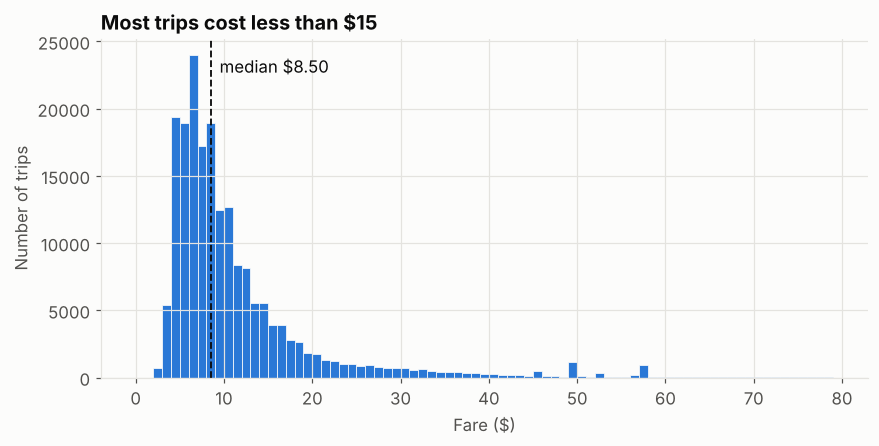

count    192012.00
mean         11.28
std           9.30
min           2.50
25%           6.00
50%           8.50
75%          12.50
max         150.83
Name: fare_amount, dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["fare_amount"], bins=np.arange(0, 80, 1), color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(df["fare_amount"].median(), color=INK, linestyle="--", linewidth=1.2)
ax.text(df["fare_amount"].median() + 1, ax.get_ylim()[1] * 0.9,
        f"median ${df['fare_amount'].median():.2f}", color=INK)
ax.set_title("Most trips cost less than $15")
ax.set_xlabel("Fare ($)")
ax.set_ylabel("Number of trips")
save(fig, "fare_distribution")
plt.show()

print(df["fare_amount"].describe().round(2))

Very right-skewed. Most rides are short and cheap, with a long tail of expensive ones (mostly airport runs, as we'll see).

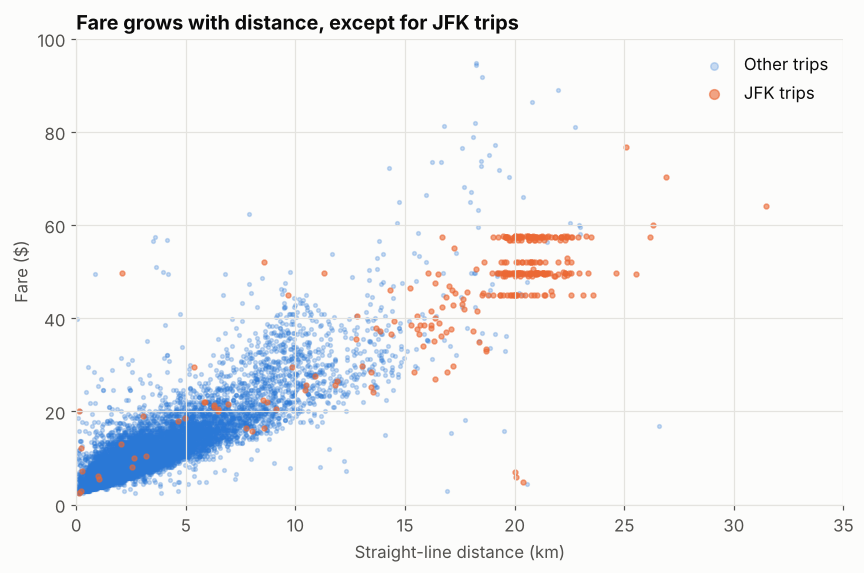

Correlation between distance and fare: 0.903


In [9]:
sample = df.sample(15000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(9, 5.5))
normal = sample[(sample["jfk_trip"] == 0)]
jfk = sample[(sample["jfk_trip"] == 1)]
ax.scatter(normal["distance_km"], normal["fare_amount"], s=6, alpha=0.25, color=BLUE, label="Other trips")
ax.scatter(jfk["distance_km"], jfk["fare_amount"], s=10, alpha=0.6, color=ORANGE, label="JFK trips")
ax.set_xlim(0, 35)
ax.set_ylim(0, 100)
ax.set_title("Fare grows with distance, except for JFK trips")
ax.set_xlabel("Straight-line distance (km)")
ax.set_ylabel("Fare ($)")
ax.legend(frameon=False, markerscale=2)
save(fig, "fare_vs_distance")
plt.show()

print("Correlation between distance and fare:", df["distance_km"].corr(df["fare_amount"]).round(3))

This was the most useful chart in the whole project. Most trips follow a clear line (roughly \$4 plus about \$2 per km). But there's a **horizontal band around \$45-\$57**. Those are JFK trips, which had a flat fare to Manhattan. A model that only knows distance will never get those right, which is why I added the airport flags.

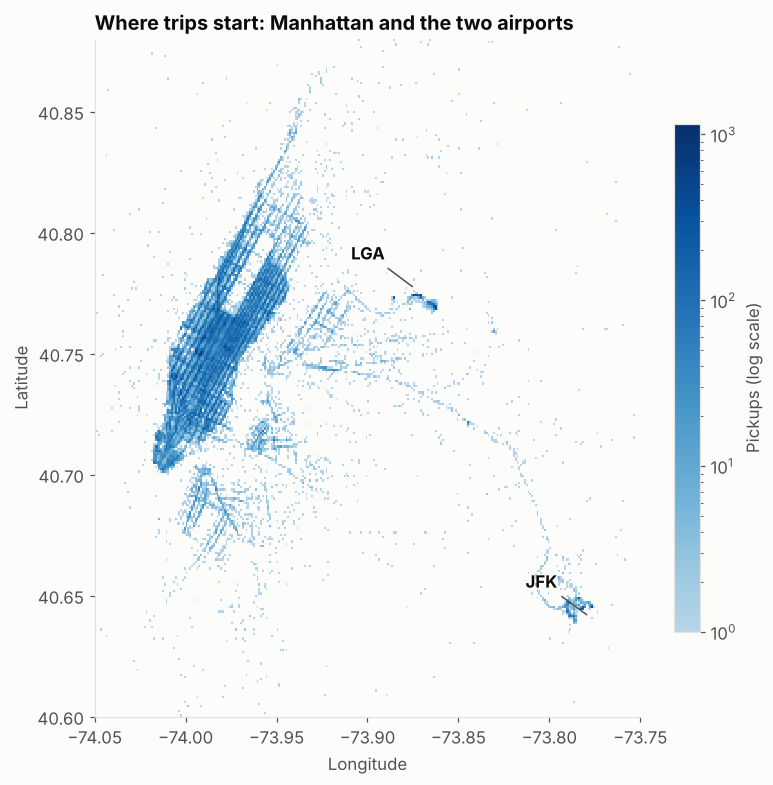

In [10]:
# start the color scale at a mid blue so areas with only a few pickups still show up
blues = mcolors.LinearSegmentedColormap.from_list("blues", plt.cm.Blues(np.linspace(0.3, 1, 256)))
fig, ax = plt.subplots(figsize=(8, 8))
h = ax.hist2d(df["pickup_longitude"], df["pickup_latitude"], bins=300,
              range=[[-74.05, -73.75], [40.60, 40.88]],
              cmap=blues, norm=mcolors.LogNorm(), cmin=1)
fig.colorbar(h[3], ax=ax, label="Pickups (log scale)", shrink=0.75)
for name, (lat, lon) in {"JFK": (40.6413, -73.7781), "LGA": (40.7769, -73.8740)}.items():
    ax.annotate(name, (lon, lat), xytext=(lon - 0.035, lat + 0.012), color=INK, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=INK_SOFT))
ax.set_title("Where trips start: Manhattan and the two airports")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(False)
save(fig, "pickup_map")
plt.show()

Just plotting the pickup coordinates basically draws a map of NYC. Manhattan is the dense strip, and you can clearly see hot spots at JFK and LaGuardia.

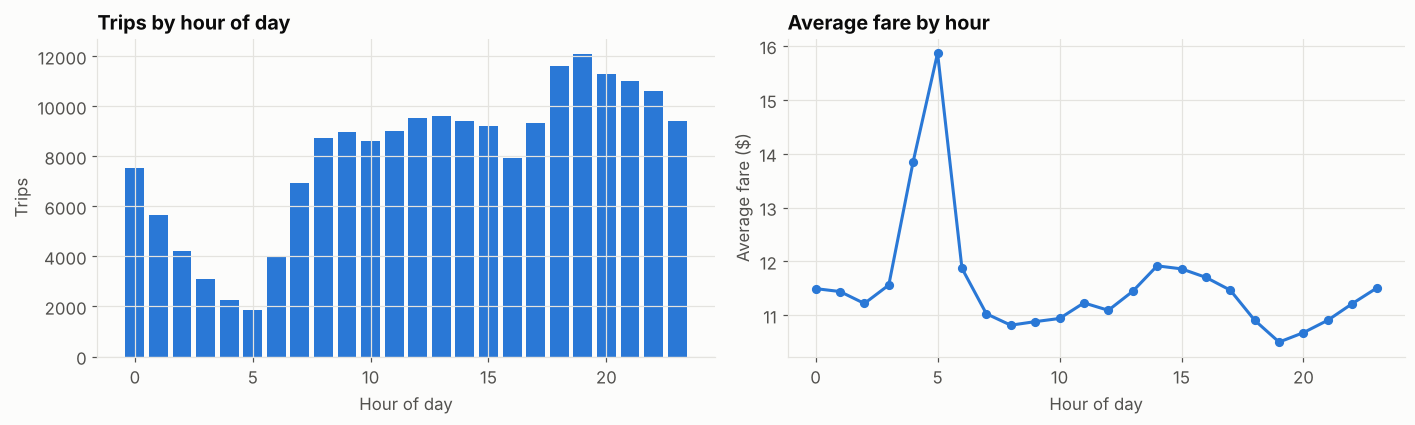

In [11]:
by_hour = df.groupby("hour").agg(trips=("fare_amount", "size"), avg_fare=("fare_amount", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(by_hour.index, by_hour["trips"], color=BLUE, width=0.8)
axes[0].set_title("Trips by hour of day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Trips")

axes[1].plot(by_hour.index, by_hour["avg_fare"], color=BLUE, linewidth=2, marker="o", markersize=5)
axes[1].set_title("Average fare by hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Average fare ($)")
fig.tight_layout()
save(fig, "trips_and_fare_by_hour")
plt.show()

Demand is lowest around 5 AM and peaks in the evening. Average fare goes the other way: early morning trips cost the most on average. That's because they tend to be longer (airport runs before flights), not because the price per km is higher.

,trips,avg_fare,avg_distance_km
trip_type,,,
Non-airport,181438,9.75,2.79
LaGuardia,6276,30.78,9.62
JFK,4037,46.10,18.30
Newark,261,71.03,17.73


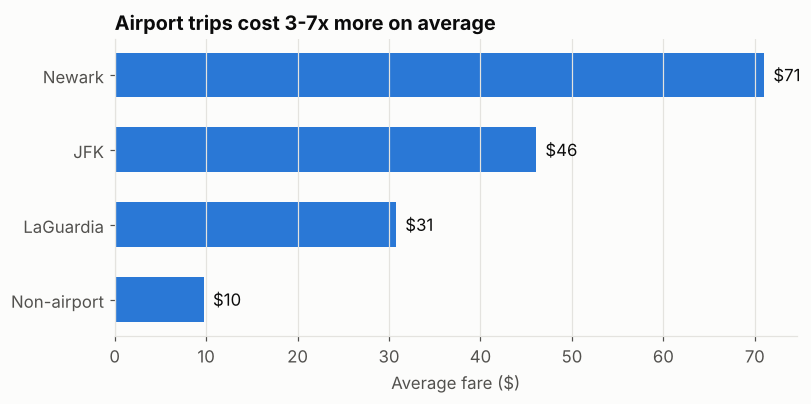

In [12]:
def trip_type(row):
    if row["jfk_trip"]: return "JFK"
    if row["ewr_trip"]: return "Newark"
    if row["lga_trip"]: return "LaGuardia"
    return "Non-airport"

df["trip_type"] = df.apply(trip_type, axis=1)
airport_summary = (df.groupby("trip_type")
                     .agg(trips=("fare_amount", "size"),
                          avg_fare=("fare_amount", "mean"),
                          avg_distance_km=("distance_km", "mean"))
                     .sort_values("avg_fare"))
display(airport_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(airport_summary.index, airport_summary["avg_fare"], color=BLUE, height=0.6)
for i, v in enumerate(airport_summary["avg_fare"]):
    ax.text(v + 1, i, f"${v:.0f}", va="center", color=INK)
ax.set_title("Airport trips cost 3-7x more on average")
ax.set_xlabel("Average fare ($)")
ax.grid(axis="y", visible=False)
save(fig, "airport_fares")
plt.show()

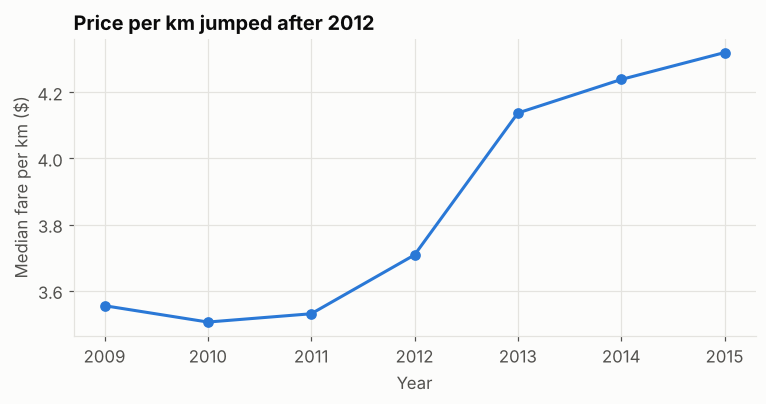

In [13]:
by_year = df.groupby("year").apply(lambda g: (g["fare_amount"] / g["distance_km"]).median())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(by_year.index, by_year.values, color=BLUE, linewidth=2, marker="o")
ax.set_title("Price per km jumped after 2012")
ax.set_ylabel("Median fare per km ($)")
ax.set_xlabel("Year")
save(fig, "fare_per_km_by_year")
plt.show()

Price per km stays flat from 2009 to 2011, starts rising in 2012 and jumps in 2013. NYC raised taxi rates in September 2012, which lines up with this. So `year` should be a useful feature even though it looked weak in the correlation matrix.

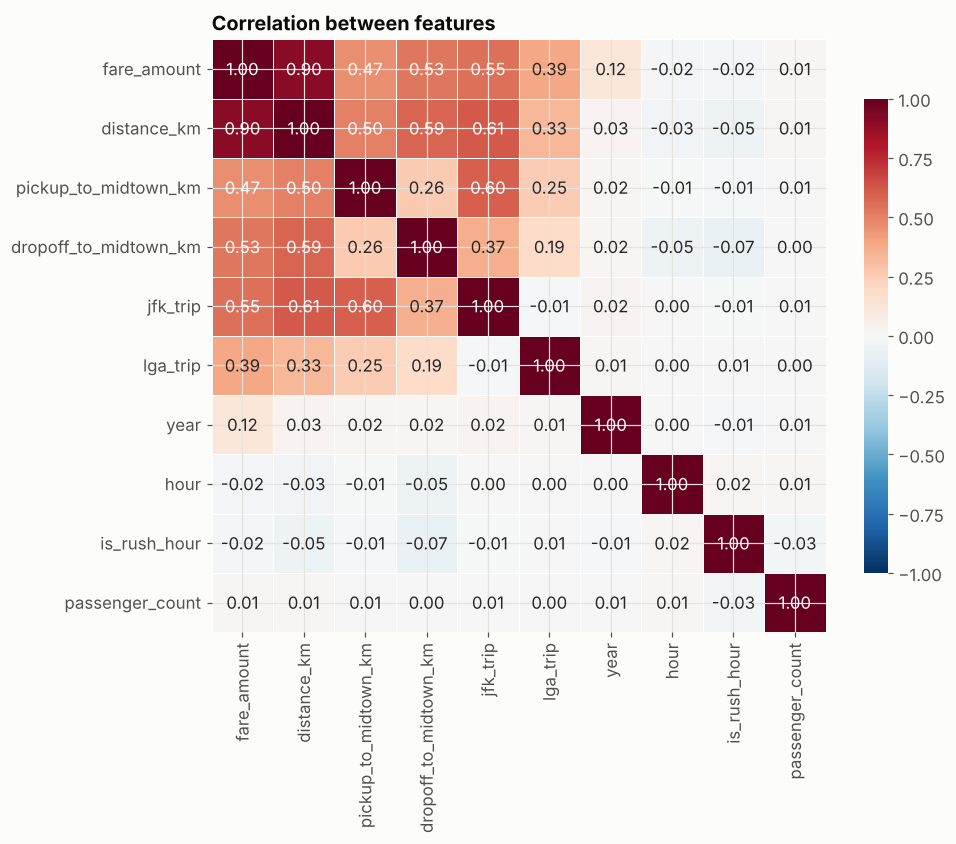

In [14]:
corr_cols = ["fare_amount", "distance_km", "pickup_to_midtown_km", "dropoff_to_midtown_km",
             "jfk_trip", "lga_trip", "year", "hour", "is_rush_hour", "passenger_count"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation between features")
plt.show()

**What I took from the EDA:**
- Distance is by far the strongest single signal (correlation 0.90 after cleaning).
- Airport trips break the distance-fare relationship, so they need their own features.
- Prices changed over time, so `year` matters.
- Hour, rush hour and passenger count barely correlate with fare on their own. Trees might still find some use for them in combination with other features.

## 6. Modeling

I split 80/20 at random. I'm comparing four models:

- **Baseline:** always predict the average fare. Any real model has to beat this.
- **Linear Regression:** simple, easy to explain.
- **Random Forest** and **XGBoost:** can handle non-linear stuff like the flat airport fares.

I also train each model twice, once with only the **basic features** (distance + time, roughly what I started with) and once with **all features**. That shows how much the location features actually helped.

Metrics: **RMSE** (in dollars, punishes big misses), **MAE** (average miss in dollars, easier to explain) and **R²**.

In [15]:
X = df[ALL_FEATURES]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (153609, 19)  Test: (38403, 19)


In [16]:
def evaluate(name, features, y_pred):
    return {
        "model": name,
        "features": features,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
    }

results = [evaluate("Baseline (mean)", "-", np.full(len(y_test), y_train.mean()))]

models = {
    "Linear Regression": lambda: LinearRegression(),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=3,
                                                   n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": lambda: xgb.XGBRegressor(n_estimators=500, max_depth=7, learning_rate=0.05,
                                        subsample=0.8, colsample_bytree=0.8,
                                        tree_method="hist", random_state=RANDOM_STATE),
}

fitted = {}
for feat_name, feats in [("basic", BASIC_FEATURES), ("all", ALL_FEATURES)]:
    for model_name, make_model in models.items():
        model = make_model().fit(X_train[feats], y_train)
        fitted[(model_name, feat_name)] = model
        results.append(evaluate(model_name, feat_name, model.predict(X_test[feats])))
        print(f"done: {model_name} ({feat_name})")

results_df = pd.DataFrame(results)
results_df.round(3)

done: Linear Regression (basic)


done: Random Forest (basic)


done: XGBoost (basic)
done: Linear Regression (all)


done: Random Forest (all)


done: XGBoost (all)


,model,features,RMSE,MAE,R2
0,Baseline (mean),-,9.226,5.871,-0.000
1,Linear Regression,basic,3.802,2.137,0.830
2,Random Forest,basic,3.544,1.973,0.852
3,XGBoost,basic,3.504,1.907,0.856
4,Linear Regression,all,3.458,1.964,0.860
5,Random Forest,all,2.954,1.569,0.897
6,XGBoost,all,2.845,1.466,0.905


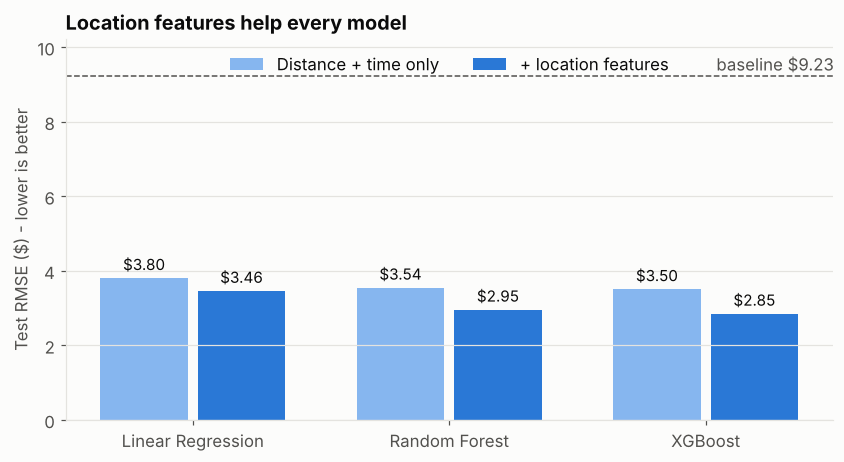

In [17]:
plot_df = results_df[results_df["features"] != "-"]
order = list(models.keys())
x = np.arange(len(order))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (feat, color, label) in enumerate([("basic", "#86b6ef", "Distance + time only"),
                                         ("all", BLUE, "+ location features")]):
    vals = plot_df[plot_df["features"] == feat].set_index("model").loc[order, "RMSE"]
    bars = ax.bar(x + (i - 0.5) * w, vals, width=w - 0.04, color=color, label=label)
    ax.bar_label(bars, fmt="$%.2f", padding=3, color=INK, fontsize=10)
baseline = results_df.loc[0, "RMSE"]
ax.axhline(baseline, color=INK_SOFT, linestyle="--", linewidth=1)
ax.text(len(order) - 0.5, baseline + 0.15, f"baseline ${baseline:.2f}", color=INK_SOFT, ha="right")
ax.set_xticks(x, order)
ax.set_ylabel("Test RMSE ($) - lower is better")
ax.set_title("Location features help every model")
ax.set_ylim(0, baseline + 1)
ax.legend(frameon=False, loc="upper center", ncol=2)
ax.grid(axis="x", visible=False)
save(fig, "model_comparison")
plt.show()

Main takeaways:

- Everything beats the baseline by a mile, as you'd expect.
- **The location features help every model**, and help XGBoost the most. That's the airport effect: tree models can learn "if JFK trip, fare is around \$52" as a rule, while linear regression can only add a fixed amount.
- **XGBoost with all features is the best**, and it trains in seconds while Random Forest takes over a minute. So XGBoost is the one I tuned.

## 7. Tuning XGBoost

I used `RandomizedSearchCV` instead of a full grid search. It tries 15 random combinations with 3-fold cross-validation, which is much faster and usually gets close to the best result anyway.

Tuning happens on the **training set only**. The test set is touched once at the end, so the final score is a fair estimate of how the model does on new data.

In [18]:
param_dist = {
    "n_estimators": [300, 500, 800],
    "max_depth": [5, 6, 7, 8, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10],
}

search = RandomizedSearchCV(
    xgb.XGBRegressor(tree_method="hist", random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"Best CV RMSE: ${-search.best_score_:.3f}")

Best params: {'subsample': 0.9, 'n_estimators': 500, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV RMSE: $2.922


In [19]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

untuned = results_df[(results_df["model"] == "XGBoost") & (results_df["features"] == "all")].iloc[0]
final = evaluate("XGBoost (tuned)", "all", y_pred)

comparison = pd.DataFrame([untuned.to_dict(), final])[["model", "RMSE", "MAE", "R2"]]
comparison.round(3)

,model,RMSE,MAE,R2
0,XGBoost,2.845,1.466,0.905
1,XGBoost (tuned),2.834,1.463,0.906


Tuning gives a small improvement over the default settings I picked. Honestly, the gain from tuning is small compared to the gain from cleaning and feature engineering. That's probably the main lesson of this project.

## 8. Evaluating the final model

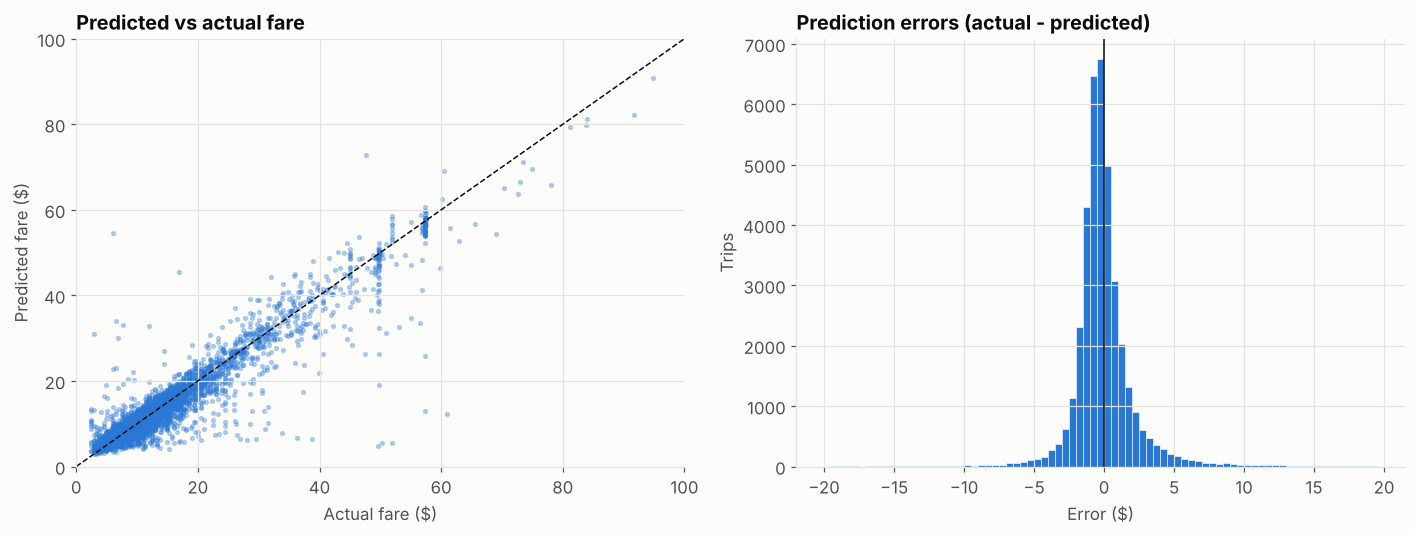

Half of predictions are within $0.88 of the actual fare
90% are within $3


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

idx = np.random.RandomState(RANDOM_STATE).choice(len(y_test), 8000, replace=False)
axes[0].scatter(y_test.iloc[idx], y_pred[idx], s=6, alpha=0.3, color=BLUE)
axes[0].plot([0, 100], [0, 100], color=INK, linewidth=1, linestyle="--")
axes[0].set_xlim(0, 100); axes[0].set_ylim(0, 100)
axes[0].set_title("Predicted vs actual fare")
axes[0].set_xlabel("Actual fare ($)")
axes[0].set_ylabel("Predicted fare ($)")

errors = y_test - y_pred
axes[1].hist(errors, bins=np.arange(-20, 20, 0.5), color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
axes[1].axvline(0, color=INK, linewidth=1)
axes[1].set_title("Prediction errors (actual - predicted)")
axes[1].set_xlabel("Error ($)")
axes[1].set_ylabel("Trips")
fig.tight_layout()
save(fig, "actual_vs_predicted")
plt.show()

print(f"Half of predictions are within ${np.median(np.abs(errors)):.2f} of the actual fare")
print(f"{(np.abs(errors) <= 3).mean():.0%} are within $3")

Most points sit close to the diagonal and the errors are centered on zero. You can see vertical stripes at \$45, \$50, \$52 and \$57, which are the flat airport fares, and the model gets most of those right. The biggest misses are in the \$30-\$60 range, where some trips the model thinks are normal city rides actually cost a lot more (probably tolls, or airport trips that started just outside the 2 km radius).

In [21]:
test_eval = X_test.copy()
test_eval["actual"] = y_test
test_eval["abs_error"] = np.abs(errors)
test_eval["distance_bucket"] = pd.cut(test_eval["distance_km"], [0, 2, 5, 10, 20, 100],
                                      labels=["0-2 km", "2-5 km", "5-10 km", "10-20 km", "20+ km"])

(test_eval.groupby("distance_bucket", observed=True)
          .agg(trips=("actual", "size"), avg_fare=("actual", "mean"), MAE=("abs_error", "mean"))
          .round(2))

,trips,avg_fare,MAE
distance_bucket,,,
0-2 km,17511,6.33,1.07
2-5 km,14077,10.56,1.38
5-10 km,4873,19.52,2.17
10-20 km,1500,35.97,3.83
20+ km,442,52.43,3.83


Errors grow with distance, which makes sense since longer trips have more room for traffic, route choice and tolls to change the price. For the short trips that make up most of the data, the model is usually off by about a dollar.

### Which features matter?

XGBoost's built-in feature importance can be misleading. It ranks features by how much they're used in splits, and binary flags like `jfk_trip` tend to look huge there. I used **permutation importance** instead: shuffle one feature and see how much worse the predictions get. A bigger drop means the model relies on it more.

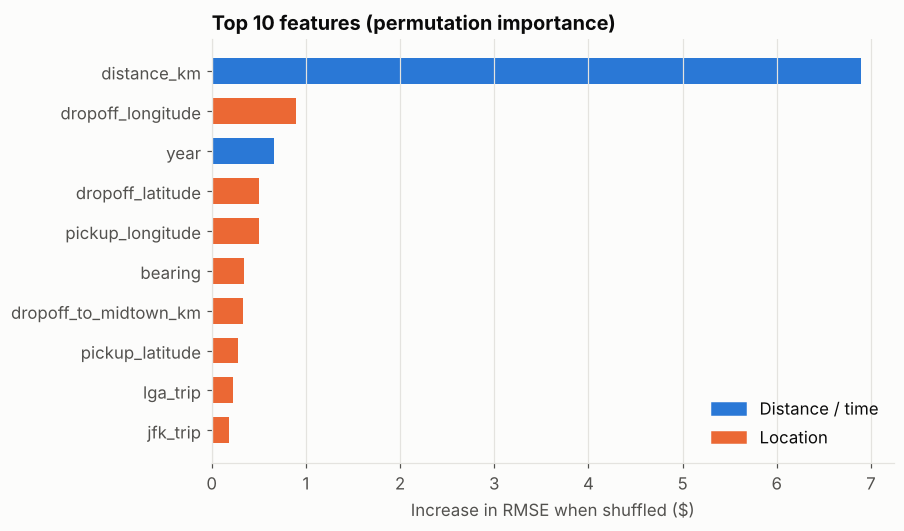

distance_km              6.897
dropoff_longitude        0.895
year                     0.666
dropoff_latitude         0.503
pickup_longitude         0.500
bearing                  0.339
dropoff_to_midtown_km    0.330
pickup_latitude          0.283
lga_trip                 0.227
jfk_trip                 0.186
pickup_to_midtown_km     0.182
hour                     0.144
month                    0.091
weekday                  0.051
is_night                 0.033
ewr_trip                 0.009
is_rush_hour             0.003
is_weekend              -0.001
passenger_count         -0.001
dtype: float64

In [22]:
perm_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), 10000, replace=False)
perm = permutation_importance(best_model, X_test.iloc[perm_idx], y_test.iloc[perm_idx],
                              scoring="neg_root_mean_squared_error", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)

imp = pd.Series(perm.importances_mean, index=ALL_FEATURES).sort_values()
top = imp.tail(10)

fig, ax = plt.subplots(figsize=(8, 5))
location = ["bearing", "pickup_to_midtown_km", "dropoff_to_midtown_km", "jfk_trip", "lga_trip", "ewr_trip",
            "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
colors = [ORANGE if f in location else BLUE for f in top.index]
ax.barh(top.index, top.values, color=colors, height=0.65)
ax.set_title("Top 10 features (permutation importance)")
ax.set_xlabel("Increase in RMSE when shuffled ($)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Distance / time"), Patch(color=ORANGE, label="Location")],
          frameon=False, loc="lower right")
save(fig, "feature_importance")
plt.show()

imp.sort_values(ascending=False).round(3)

Distance is still the most important feature by far. After that comes **where the trip ends** (dropoff coordinates), then `year`, which matches the fare increase from the EDA. Most of the rest of the top 10 is location: pickup point, direction of travel, distance to Midtown and the airport flags. Passenger count and the rush hour flag hardly matter at all.

## 9. Wrap-up

In [23]:
summary = results_df[results_df["features"].isin(["-", "all"])][["model", "RMSE", "MAE", "R2"]]
summary = pd.concat([summary, pd.DataFrame([final])[["model", "RMSE", "MAE", "R2"]]], ignore_index=True)
summary.round(3)

,model,RMSE,MAE,R2
0,Baseline (mean),9.226,5.871,-0.000
1,Linear Regression,3.458,1.964,0.860
2,Random Forest,2.954,1.569,0.897
3,XGBoost,2.845,1.466,0.905
4,XGBoost (tuned),2.834,1.463,0.906


### What worked
- **Cleaning the data properly made a big difference.** Removing impossible fares, passenger counts and coordinates gets rid of noise the model would otherwise try to fit.
- **Location features mattered more than the model choice.** Adding airport flags, distance to Midtown, direction and coordinates cut XGBoost's RMSE by almost 20% compared to distance + time only.
- **XGBoost** came out best, and it's also much faster to train than Random Forest on this data.

### Limitations
- Straight-line distance isn't the real driving distance. Routing data (e.g. from OSRM) would likely help a lot for longer trips.
- There's no traffic, weather or surge pricing information, which explains some of the leftover error.
- The data is from 2009-2015, so the model wouldn't apply to today's prices without retraining.
- I used a random split. For a model that would actually be deployed, training on older trips and testing on newer ones would be a more realistic check.

### What I'd try next
- Add actual route distance and travel time
- Join historical weather data (rain probably increases fares and demand)
- Try a time-based train/test split
- Wrap the model in a small API (FastAPI) so it can return a fare estimate for a given trip